# Lore — TVSum Highlight-Detection Ablation (Modal)

**Goal:** show that **raw audio events** (waves, birds, crowd, engine) improve zero-shot highlight detection on **TVSum**, on top of speech captions. A frozen **Qwen2.5-VL-3B** rates per-2s saliency under three input conditions:

- **V**     - video frames only
- **V+C**   - video + speech transcript (Whisper ASR)
- **V+C+A** - video + speech + non-speech sound events (AST audio tagging)

**Idempotent by design** - every download / extract / inference step checks for an existing artifact (on the Modal Volume or locally) and skips work it already did. Re-running any cell is safe and cheap. Flip a `FORCE_*` flag in Cell 2 to intentionally redo a step.

**Run order:** Cells 1->7 once (setup, ~15-25 min, mostly the one-time image build + downloads). Then 8->12 for results. Cell 13 (VLM-as-judge) is optional. Per-cell timings are in the final cell.

In [17]:
# 1) Install + authenticate Modal (idempotent: skips token flow if already configured)
%uv pip install -q modal scipy h5py
import os, modal
have_tok = os.path.exists(os.path.expanduser("~/.modal.toml")) or ("MODAL_TOKEN_ID" in os.environ)
if not have_tok:
    print("No Modal token found - launching `modal token new` (opens a URL to approve).")
    get_ipython().system("modal token new")
else:
    print("Modal token already configured - skipping auth.")

Note: you may need to restart the kernel to use updated packages.
Modal token already configured - skipping auth.


In [18]:
# 2) Central config - paths, conditions, GPU, data sources, FORCE flags
VOL_NAME   = "lore-tvsum-data"   # separate Volume; safe to reuse across runs
DATA       = "/data"            # mount point inside Modal containers
SMOKE_GPU  = "A10G"             # light GPU for model prefetch
FULL_GPU   = "A100-40GB"        # avoids OOM on long TVSum videos (up to ~650s)

CLIP_LEN   = 2.0                # seconds per saliency bin (matches TVSum 2s shots)
BASE_FPS   = 1.0               # target sampling fps ...
MAX_FRAMES = 96     # was 128 — fewer frames = faster + less memory for the raw-audio pass
MAX_PIXELS = 256*28*28        # per-frame video budget; MUST be >= Qwen VIDEO_MIN_PIXELS (128*28*28)
MAX_NEW_TOKENS = 1536
MAX_SEG    = 40                # model rates this many coarse segments/video,
#                               expanded to 2s bins for eval (avoids long-list decode collapse)
CONDITIONS = ["v", "vc", "vca"]

TVSUM_DIR  = "tvsum_data"
TVSUM_MAT  = f"{TVSUM_DIR}/ydata-tvsum50.mat"     # official ground truth (v7.3 HDF5)
MAT_URLS   = ["https://raw.githubusercontent.com/yalesong/tvsum/master/matlab/ydata-tvsum50.mat"]
# If the URL ever dies, download ydata-tvsum50.mat from people.csail.mit.edu/yalesong/tvsum
# and drop it at TVSUM_MAT by hand. The 50 video ids ARE their YouTube ids (used in Cell 5/7).
TVSUM_PKG_URLS = ["https://people.csail.mit.edu/yalesong/tvsum/tvsum50_ver_1_1.tgz"]
# Official package: 641MB .tgz, ALL 50 videos (incl. ones now deleted from YouTube).

RECORDS_PATH = "records_omni.json"   # cached GPU outputs; results cells reuse this

FORCE_ANNO = FORCE_VIDEOS = FORCE_AUDIO = FORCE_PREFETCH = FORCE_INFER = False
N_VIDEOS = 50                 # cap TVSum videos (50 = full set); lower for a faster pass

In [19]:
# 3) TVSum ground truth from the official .mat (idempotent download + per-2s binning)
import os, urllib.request, numpy as np, h5py
os.makedirs(TVSUM_DIR, exist_ok=True)
if FORCE_ANNO or not (os.path.exists(TVSUM_MAT) and os.path.getsize(TVSUM_MAT) > 0):
    for u in MAT_URLS:
        try:
            urllib.request.urlretrieve(u, TVSUM_MAT)
            if os.path.getsize(TVSUM_MAT) > 0: print("downloaded", TVSUM_MAT); break
        except Exception as e:
            print("  miss", u, "::", repr(e)[:80])
else:
    print("have", TVSUM_MAT)
assert os.path.exists(TVSUM_MAT) and os.path.getsize(TVSUM_MAT) > 0, \
    "ydata-tvsum50.mat missing - grab it from people.csail.mit.edu/yalesong/tvsum"

# v7.3 .mat = HDF5. gt_score is PER-FRAME; downsample to per-2s bins to match the model output.
f = h5py.File(TVSUM_MAT, "r"); grp = f["tvsum50"]
_S = lambda ref: "".join(chr(int(c)) for c in np.array(f[ref]).ravel())
_N = lambda ref: np.array(f[ref]).ravel()

gt_importance, examples = {}, []
for i in range(grp["video"].shape[0]):
    vid = _S(grp["video"][i][0]); dur = float(_N(grp["length"][i][0])[0])
    gtf = _N(grp["gt_score"][i][0]).astype(float)
    fps = len(gtf) / max(dur, 1e-6)
    n   = max(1, int(round(dur / CLIP_LEN)))
    win = max(1, int(round(CLIP_LEN * fps)))               # frames per 2s bin
    gt_importance[vid] = [float(gtf[j*win:(j+1)*win].mean()) for j in range(n) if j*win < len(gtf)]
    examples.append({"vid": vid, "yt": vid, "title": _S(grp["title"][i][0]),
                     "category": _S(grp["category"][i][0]), "duration": dur})
f.close()
examples = examples[:N_VIDEOS]
print(len(examples), "TVSum videos; total", f'{sum(e["duration"] for e in examples)/60:.0f} min')
print("  example:", examples[0]["vid"], "|", examples[0]["title"][:45],
      "| gt bins =", len(gt_importance[examples[0]["vid"]]))

have tvsum_data/ydata-tvsum50.mat
50 TVSum videos; total 210 min
  example: AwmHb44_ouw | #1306 How to change tires for off road vehicl | gt bins = 177


In [20]:
# 4) Modal app, image, Volume  (Qwen2.5-Omni: native raw-audio + video)
import modal
app   = modal.App("lore-tvsum")
vol   = modal.Volume.from_name(VOL_NAME, create_if_missing=True)
image = (
    modal.Image.debian_slim(python_version="3.12")
    .apt_install("ffmpeg")
    .pip_install("torch", "torchvision", "accelerate",
                 "transformers>=4.52",          # Qwen2.5-Omni support (use git+ source if import fails)
                 "qwen-omni-utils[decord]",
                 "librosa", "soundfile",
                 "openai-whisper")              # still used for the V+C speech-caption text
    .env({"HF_HOME": f"{DATA}/hf"})
)

In [21]:
# 5) Remote functions: fetch / list / extract-audio / prefetch - all idempotent
import modal

@app.function(image=image, volumes={DATA: vol}, timeout=60*60, serialized=True)
def fetch_videos(specs, pkg_urls):
    # Idempotent. PREFERRED: download the official TVSum package (.tgz/.zip) ONCE and extract all
    # 50 mp4s to the Volume. yt-dlp by YouTube id is only a last-resort fallback for stragglers.
    import os, subprocess, tarfile, zipfile, glob, shutil, urllib.request
    vdir = f"{DATA}/videos"; os.makedirs(vdir, exist_ok=True)
    present = lambda v: os.path.exists(f"{vdir}/{v}.mp4") and os.path.getsize(f"{vdir}/{v}.mp4") > 0

    if any(not present(s["vid"]) for s in specs) and pkg_urls:
        tmp = "/tmp/_tvsum_extract"                      # container-local; keeps Volume clean
        for u in pkg_urls:
            pkg = "/tmp/_tvsum_pkg" + (".zip" if u.lower().endswith(".zip") else ".tgz")
            try:
                if not (os.path.exists(pkg) and os.path.getsize(pkg) > 1_000_000):
                    print("downloading package:", u)
                    with urllib.request.urlopen(u, timeout=120) as r, open(pkg + ".part", "wb") as out:
                        shutil.copyfileobj(r, out, length=1024*1024)
                    os.replace(pkg + ".part", pkg)
                print(f"extracting {os.path.getsize(pkg)//(1024*1024)} MB ...")
                shutil.rmtree(tmp, ignore_errors=True); os.makedirs(tmp, exist_ok=True)
                if zipfile.is_zipfile(pkg):
                    with zipfile.ZipFile(pkg) as z: z.extractall(tmp)
                else:
                    with tarfile.open(pkg, "r:*") as t:
                        try: t.extractall(tmp, filter="data")     # py>=3.12
                        except TypeError: t.extractall(tmp)
                # TVSum tgz nests the videos in ydata-tvsum50-video.zip -> extract that too
                for zf in glob.glob(f"{tmp}/**/*.zip", recursive=True):
                    if "video" in os.path.basename(zf).lower():
                        with zipfile.ZipFile(zf) as z: z.extractall(os.path.dirname(zf))
                copied = 0
                for mp4 in glob.glob(f"{tmp}/**/*.mp4", recursive=True):
                    v = os.path.splitext(os.path.basename(mp4))[0]
                    if not present(v): shutil.copy(mp4, f"{vdir}/{v}.mp4"); copied += 1
                print(f"copied {copied} videos from package")
                shutil.rmtree(tmp, ignore_errors=True)
                try: os.remove(pkg)
                except OSError: pass
                break
            except Exception as e:
                print("package miss", u, "::", repr(e)[:140])
                shutil.rmtree(tmp, ignore_errors=True)

    for s in specs:                                       # last-resort fallback
        if present(s["vid"]): continue
        out = f"{vdir}/{s['vid']}.mp4"
        cmd = ["yt-dlp", "-q", "--no-warnings", "--no-playlist",
               "--extractor-args", "youtube:player_client=android,ios,web",
               "--retries", "3", "--geo-bypass", "-f", "mp4/bv*[ext=mp4]+ba/b",
               "--recode-video", "mp4", "-o", out, f"https://www.youtube.com/watch?v={s['yt']}"]
        subprocess.run(cmd, capture_output=True, text=True)
        if present(s["vid"]): print("yt-dlp ok", s["vid"])

    vol.commit()
    return sorted(s["vid"] for s in specs if present(s["vid"]))

@app.function(image=image, volumes={DATA: vol}, serialized=True)
def list_videos():
    import os
    d = f"{DATA}/videos"
    return sorted(f[:-4] for f in os.listdir(d) if f.endswith(".mp4")) if os.path.isdir(d) else []

@app.function(image=image, volumes={DATA: vol}, cpu=8.0, timeout=60*60, serialized=True)
def extract_audio():
    import os, subprocess
    from concurrent.futures import ThreadPoolExecutor
    d = f"{DATA}/videos"
    vids = [f[:-4] for f in os.listdir(d) if f.endswith(".mp4")]
    def one(v):
        wav = f"{d}/{v}.16k.wav"
        if os.path.exists(wav) and os.path.getsize(wav) > 0: return 0
        subprocess.run(["ffmpeg", "-y", "-i", f"{d}/{v}.mp4", "-ac", "1", "-ar", "16000", wav],
                       stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        return 1
    with ThreadPoolExecutor(max_workers=8) as pool: made = sum(pool.map(one, vids))
    vol.commit()
    return f"{made} new WAVs ({len(vids)} videos total)"

@app.function(image=image, volumes={DATA: vol}, gpu=SMOKE_GPU, timeout=60*60, serialized=True)
def prefetch_models(force=False):
    import os
    marker = f"{DATA}/.prefetch_done"
    if os.path.exists(marker) and not force:
        return "models already cached (marker present)"
    from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, pipeline
    import whisper
    Qwen2_5_VLForConditionalGeneration.from_pretrained("Qwen/Qwen2.5-VL-3B-Instruct", torch_dtype="auto", device_map="auto")
    AutoProcessor.from_pretrained("Qwen/Qwen2.5-VL-3B-Instruct")
    whisper.load_model("base", download_root=f"{DATA}/whisper")
    pipeline("audio-classification", model="MIT/ast-finetuned-audioset-10-10-0.4593", device=0)
    open(marker, "w").write("ok"); vol.commit()
    return "models cached on volume"

In [22]:
# 6) GPU worker - Qwen2.5-Omni-7B: V (frames) / V+C (frames+ASR text) / V+C+A (frames+ASR text+RAW AUDIO)
import modal

@app.cls(image=image, gpu=FULL_GPU, volumes={DATA: vol}, timeout=60*60, max_containers=10, serialized=True)
class Predictor:
    @modal.enter()
    def load(self):
        import torch
        from transformers import Qwen2_5OmniForConditionalGeneration, Qwen2_5OmniProcessor
        import whisper
        self.torch = torch
        self.model = Qwen2_5OmniForConditionalGeneration.from_pretrained(
            "Qwen/Qwen2.5-Omni-7B", torch_dtype="auto", device_map="auto",
            enable_audio_output=False)          # text-only -> skip the speech 'talker' (~10GB saved)
        # if that kwarg errors on your transformers: drop it, then call self.model.disable_talker()
        self.processor = Qwen2_5OmniProcessor.from_pretrained("Qwen/Qwen2.5-Omni-7B")
        self.asr = whisper.load_model("base", download_root=f"{DATA}/whisper")

    @modal.method()
    def predict_batch(self, job):
        import re, os
        import numpy as np
        torch = self.torch
        from qwen_omni_utils import process_mm_info
        examples, cfg = job["examples"], job["cfg"]
        CLIP_LEN, DATA = cfg["CLIP_LEN"], cfg["DATA"]
        MAX_FRAMES, BASE_FPS = cfg["MAX_FRAMES"], cfg["BASE_FPS"]
        MAX_PIXELS, MAX_NEW, CONDS = cfg["MAX_PIXELS"], cfg["MAX_NEW_TOKENS"], cfg["CONDITIONS"]
        MAX_SEG, DEBUG = cfg.get("MAX_SEG", 40), cfg.get("DEBUG", False)
        SYS = {"role": "system", "content": [{"type": "text",
               "text": "You are Qwen, a helpful assistant that watches and listens to videos."}]}

        def build_prompt(title, duration, n_seg, seg_len, speech=None, has_audio=False):
            p = ("You are rating an amateur video" + (f' titled "{title}"' if title else "")
                 + f" for a highlights reel.\nThe {duration:.0f}s video is split into {n_seg} equal "
                 f"segments of ~{seg_len:.0f}s each, in time order.\n")
            if speech: p += "\nSPEECH TRANSCRIPT ([start-end]s):\n" + speech + "\n"
            srcs = "the visual frames"
            if speech: srcs += " and the speech transcript"
            if has_audio: srcs += " and the video's RAW AUDIO (ambient sounds: water, wind, birds, crowd, engines, plus speech tone)"
            p += ("\nUsing " + srcs + f", rate how highlight-worthy each of the {n_seg} segments is on a "
                  "0-4 scale (4 = must-keep highlight, 0 = boring). Use the FULL range. Reply with ONLY "
                  f"compact JSON of exactly {n_seg} integers, no prose:\n" + '{"saliency":[s0,s1,...]}')
            return p

        def parse_nums(reply):
            m = (re.search(r'saliency"?\s*:\s*\[([^\]]*)\]', reply, re.DOTALL)
                 or re.search(r'saliency"?\s*:\s*\[([0-9,\s\.\+\-eE]*)', reply, re.DOTALL)
                 or re.search(r'\[([0-9][0-9,\s\.\+\-eE]*)\]', reply, re.DOTALL))
            nums = []
            if m:
                for tok in m.group(1).split(","):
                    tok = tok.strip()
                    if not tok: continue
                    try: nums.append(float(tok))
                    except ValueError: pass
            return nums

        def expand(nums, n):
            if not nums: return [0.0]*n
            k = len(nums)
            return [nums[min(k-1, int(j*k/n))] for j in range(n)]

        @torch.inference_mode()
        def run_omni(vp, prompt, fps, use_audio, temperature):
            conv = [SYS, {"role": "user", "content": [
                {"type": "video", "video": vp, "fps": fps, "max_pixels": MAX_PIXELS},
                {"type": "text", "text": prompt}]}]
            text = self.processor.apply_chat_template(conv, add_generation_prompt=True, tokenize=False)
            audios, images, videos = process_mm_info(conv, use_audio_in_video=use_audio)
            inp = self.processor(text=text, audio=audios, images=images, videos=videos,
                                 return_tensors="pt", padding=True,
                                 use_audio_in_video=use_audio).to(self.model.device)
            gen = dict(max_new_tokens=MAX_NEW, do_sample=temperature > 0, return_audio=False)
            if temperature > 0: gen.update(temperature=temperature, top_p=0.9)
            torch.manual_seed(1234)
            out = self.model.generate(**inp, **gen)
            ids = out[0] if isinstance(out, (tuple, list)) else out      # tuple if talker enabled
            return self.processor.batch_decode(ids[:, inp["input_ids"].shape[1]:], skip_special_tokens=True)[0]

        def scores_for(vp, prompt, fps, use_audio):
            nums, reply = [], ""
            for temp in (0.7, 1.0):
                reply = run_omni(vp, prompt, fps, use_audio, temp)
                nums = parse_nums(reply)
                if len({round(x, 3) for x in nums}) > 1: break
            return nums, reply

        def speech_text(vid):
            wav = f"{DATA}/videos/{vid}.16k.wav"
            src = wav if os.path.exists(wav) else f"{DATA}/videos/{vid}.mp4"
            lines = []
            for sg in self.asr.transcribe(src, fp16=True)["segments"]:
                t = sg["text"].strip()
                if t: lines.append((sg["start"], sg["end"], '"' + t + '"'))
            return "\n".join(f"[{a:.0f}-{b:.0f}s] {x}" for a, b, x in sorted(lines))

        results = []
        for ex in examples:
            dur = ex["duration"]; n = int(round(dur / CLIP_LEN)); vp = f"{DATA}/videos/{ex['vid']}.mp4"
            rec = {"vid": ex["vid"], "title": ex.get("title", ""), "duration": dur, "n": n}
            if not os.path.exists(vp):
                for c in CONDS: rec[c] = [0.0]*n
                results.append(rec); continue
            n_seg = max(2, min(MAX_SEG, n)); seg_len = dur / n_seg
            fps = min(BASE_FPS, MAX_FRAMES / max(dur, 1.0))
            sp = speech_text(ex["vid"])
            plan = {"v":   (build_prompt(ex.get("title", ""), dur, n_seg, seg_len), False),
                    "vc":  (build_prompt(ex.get("title", ""), dur, n_seg, seg_len, speech=sp or None), False),
                    "vca": (build_prompt(ex.get("title", ""), dur, n_seg, seg_len, speech=sp or None, has_audio=True), True)}
            raw = {}
            for c in CONDS:
                prompt, use_audio = plan[c]
                nums, reply = scores_for(vp, prompt, fps, use_audio)
                raw[c] = reply
                rec[c] = expand(nums, n)
            if DEBUG: rec["raw"] = {c: raw[c][:600] for c in CONDS}
            results.append(rec)
        return results

In [23]:
# 7) ONE-TIME setup (idempotent): videos -> audio -> model cache. Safe to re-run.
specs = [{"vid": e["vid"], "yt": e["yt"]} for e in examples]
with modal.enable_output(), app.run():
    got = fetch_videos.remote(specs, TVSUM_PKG_URLS)
    print(f"videos on volume: {len(got)}/{len(specs)}")
    print("audio:", extract_audio.remote())
    print("models:", prefetch_models.remote(FORCE_PREFETCH))

✓ Initialized. View run at https://modal.com/apps/tejasvityagi1414/main/ap-wQqJ7MjUR2PL3AJVEZRSfo
⠋ Initializing...
⠸ Creating objects...
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── ⠋ Creating function extract_audio...
├── ⠋ Creating function prefetch_models...
⠸ Creating objects...
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
└── 🔨 Created function Predictor.*.
✓ Created objects.
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
└── 🔨 Created function Predictor.*.
⠹ Loading images (1 containers initializing)... View app at 
⠴ Loading images (1 containers initializing)... View app at 
⠇ Loading images (1 containers initializing)... View app at 
⠙ Loading images (1 containers initializing)... View app at 
⠴ Loading images (1 containers initializing)..

In [24]:
# 8) Build the eval set from videos actually present (no downloads)
with modal.enable_output(), app.run():
    have = set(list_videos.remote())
eval_set = [e for e in examples if e["vid"] in have]
print(f"{len(eval_set)}/{len(examples)} videos present; evaluating {len(eval_set)}")

✓ Initialized. View run at https://modal.com/apps/tejasvityagi1414/main/ap-GYQ5CcXrkf6v6owRYbYjUr
⠋ Initializing...
⠸ Creating objects...
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── ⠋ Creating function extract_audio...
├── ⠋ Creating function prefetch_models...
⠸ Creating objects...
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
└── 🔨 Created function Predictor.*.
✓ Created objects.
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
└── 🔨 Created function Predictor.*.
⠇ Loading images (1 containers initializing)... View app at 
⠹ Loading images (1 containers initializing)... View app at 
⠴ Loading images (1 containers initializing)... View app at 
⠇ Loading images (1 containers initializing)... View app at 
⠙ Loading images (1 containers initializing)..

In [25]:
# 9) Smoke test - ONE video, verify parsing + 3 conditions before the full run
cfg = {"CLIP_LEN": CLIP_LEN, "DATA": DATA, "MAX_FRAMES": MAX_FRAMES, "BASE_FPS": BASE_FPS,
       "MAX_PIXELS": MAX_PIXELS, "MAX_NEW_TOKENS": MAX_NEW_TOKENS, "CONDITIONS": CONDITIONS,
       "MAX_SEG": MAX_SEG, "DEBUG": True}
if eval_set:
    with modal.enable_output(), app.run():
        smoke = Predictor().predict_batch.remote({"examples": [eval_set[0]], "cfg": cfg})
    r = smoke[0]
    print("vid", r["vid"], "| n", r["n"], "| dur", round(r["duration"], 1))
    for c in CONDITIONS:
        nz = sum(1 for x in r[c] if x > 0); uniq = sorted(set(round(x, 1) for x in r[c]))
        print(f"  {c:4s} nonzero={nz}/{r['n']}  values={uniq}  saliency[:16]={[round(x,1) for x in r[c][:16]]}")
    print("\n--- raw model replies (first 400 chars) ---")
    for c in CONDITIONS:
        print(f"[{c}]", r.get("raw", {}).get(c, "")[:400].replace(chr(10), " "), "\n")

✓ Initialized. View run at https://modal.com/apps/tejasvityagi1414/main/ap-0hX1nDbI91pIcMWVYjqnQa
⠋ Initializing...
⠸ Creating objects...
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
⠼ Creating objects...
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
└── 🔨 Created function Predictor.*.
✓ Created objects.
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
└── 🔨 Created function Predictor.*.
⠇ Loading images (1 containers initializing)... View app at 
⠙ Loading images (1 containers initializing)... View app at 
⠼ Loading images (1 containers initializing)... View app at 
⠧ Loading images (1 containers initializing)... View app at 
⠋ Loading images (1 containers initializing)... View

In [26]:
# 10) Full run - RESUMABLE: saves after each shard, skips done videos, tolerates shard failures
import json, os
def chunk(xs, k): return [xs[i:i+k] for i in range(0, len(xs), k)]
cfg = {"CLIP_LEN": CLIP_LEN, "DATA": DATA, "MAX_FRAMES": MAX_FRAMES, "BASE_FPS": BASE_FPS,
       "MAX_PIXELS": MAX_PIXELS, "MAX_NEW_TOKENS": MAX_NEW_TOKENS, "CONDITIONS": CONDITIONS, "MAX_SEG": MAX_SEG}

records = []
if os.path.exists(RECORDS_PATH) and not FORCE_INFER:
    try: records = json.load(open(RECORDS_PATH))
    except Exception: records = []
done = {r["vid"] for r in records}
todo = [e for e in eval_set if e["vid"] not in done]
print(f"{len(done)} already done, {len(todo)} to go (of {len(eval_set)})")

if todo:
    jobs = [{"examples": s, "cfg": cfg} for s in chunk(todo, 2)]   # small shards = frequent checkpoints
    with modal.enable_output(), app.run():
        async for b in Predictor().predict_batch.map.aio(jobs, return_exceptions=True):
            if isinstance(b, Exception):
                print("  shard failed (skipped):", repr(b)[:120]); continue
            records.extend(b)
            json.dump(records, open(RECORDS_PATH, "w"))     # checkpoint immediately
            print(f"  saved {len(records)}/{len(eval_set)}")
print(f"total {len(records)} predictions in {RECORDS_PATH}")

15 already done, 35 to go (of 50)
✓ Initialized. View run at https://modal.com/apps/tejasvityagi1414/main/ap-Ug2SIv291AoeisAMgRRSqT
⠋ Initializing...
⠸ Creating objects...
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
⠸ Creating objects...
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
└── 🔨 Created function Predictor.*.
✓ Created objects.
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
└── 🔨 Created function Predictor.*.
⠸ Running app...
╭──────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Predictor.predict_batch ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  0/18 -:--:--                               │
⠦ Running app...
╭─

In [27]:
# 11) TVSum metrics - Spearman rho + Kendall tau (primary), top-5 mAP (secondary)
import numpy as np
from scipy.stats import spearmanr, kendalltau

def _align(pred, gt):
    m = min(len(pred), len(gt)); return np.array(pred[:m], float), np.array(gt[:m], float)

def _top5_ap(pred, gt):
    # positives = top-20% GT shots; average precision of the predicted ranking (TVSum highlight proxy)
    p, g = _align(pred, gt)
    if len(g) < 5: return np.nan
    pos = set(np.argsort(-g)[:max(1, int(round(0.2*len(g))))].tolist())
    hit = ap = 0.0
    for rank, idx in enumerate(np.argsort(-p).tolist(), 1):
        if idx in pos: hit += 1; ap += hit/rank
    return ap/len(pos)

def score(records, cond):
    rho = tau = mapv = 0.0; nv = 0
    for r in records:
        gt = gt_importance.get(r["vid"])
        if not gt: continue
        p, g = _align(r[cond], gt)
        if len(p) < 3 or np.std(p) == 0 or np.std(g) == 0:
            s = k = 0.0
        else:
            s = spearmanr(p, g).correlation; k = kendalltau(p, g).correlation
        rho += 0.0 if np.isnan(s) else s
        tau += 0.0 if np.isnan(k) else k
        mapv += _top5_ap(r[cond], gt); nv += 1
    nv = max(nv, 1)
    return {"Spearman": rho/nv, "Kendall": tau/nv, "top5_mAP": mapv/nv, "n": nv}

res = {c: score(records, c) for c in CONDITIONS}
names = {"v": "V (visual)", "vc": "V+C (+speech)", "vca": "V+C+A (+sound)"}
print(f'{"condition":18s}{"Spearman":>10}{"Kendall":>10}{"top5_mAP":>10}')
for c in CONDITIONS:
    d = res[c]; print(f'{names[c]:18s}{d["Spearman"]:10.4f}{d["Kendall"]:10.4f}{d["top5_mAP"]:10.4f}')
print(f'\n(n={res["v"]["n"]} videos)  delta V+C+A vs V: '
      f'Spearman {res["vca"]["Spearman"]-res["v"]["Spearman"]:+.4f}, '
      f'top5_mAP {res["vca"]["top5_mAP"]-res["v"]["top5_mAP"]:+.4f}')

condition           Spearman   Kendall  top5_mAP
V (visual)            0.0396    0.0307    0.2248
V+C (+speech)         0.0454    0.0371    0.2238
V+C+A (+sound)        0.0251    0.0205    0.2231

(n=50 videos)  delta V+C+A vs V: Spearman -0.0145, top5_mAP -0.0016


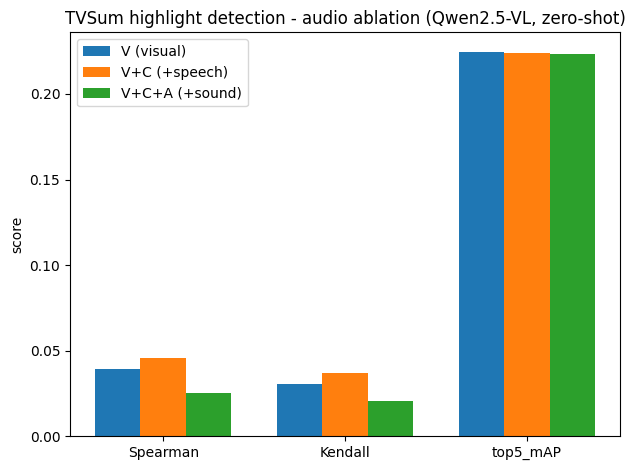

In [28]:
# 12) Comparison plot - does raw audio help?
import matplotlib.pyplot as plt, numpy as np
mets = ["Spearman", "Kendall", "top5_mAP"]; x = np.arange(len(mets)); w = 0.25
for i, c in enumerate(CONDITIONS):
    plt.bar(x + i*w, [res[c][m] for m in mets], w, label=names[c])
plt.xticks(x + w, mets); plt.ylabel("score")
plt.title("TVSum highlight detection - audio ablation (Qwen2.5-VL, zero-shot)")
plt.legend(); plt.tight_layout(); plt.savefig("tvsum_audio_ablation.png", dpi=150); plt.show()

In [29]:
# 13) (Optional) Qwen-VL-as-judge: does +sound pick better highlights than visual-only?
JUDGE_MODEL = "Qwen/Qwen2.5-VL-7B-Instruct"; TOPK = 6; run_judge = True  # set True to run

@app.cls(image=image, gpu=FULL_GPU, volumes={DATA: vol}, timeout=60*60, max_containers=6, serialized=True)
class Judge:
    @modal.enter()
    def load(self):
        import torch
        from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration
        self.torch = torch
        self.m = Qwen2_5_VLForConditionalGeneration.from_pretrained(JUDGE_MODEL, torch_dtype="auto", device_map="auto")
        self.p = AutoProcessor.from_pretrained(JUDGE_MODEL)

    @modal.method()
    def vote(self, job):
        import numpy as np, re, random
        from qwen_vl_utils import process_vision_info
        torch = self.torch; items, cfg = job["items"], job["cfg"]
        spans = lambda sal, k: ", ".join(f"{i*2}-{i*2+2}s" for i in sorted(int(j) for j in np.argsort(-np.array(sal, float))[:k]))
        out = []
        for it in items:
            flip = random.random() < 0.5
            s1, s2 = (it["vca"], it["v"]) if not flip else (it["v"], it["vca"])
            prompt = ("Two editors picked the highlight moments of this video.\n"
                      f"Editor 1 kept: {spans(s1, TOPK)}.\nEditor 2 kept: {spans(s2, TOPK)}.\n"
                      "Which editor better captured the genuinely interesting/important moments? "
                      'Reply ONLY compact JSON: {"winner":1} or {"winner":2}.')
            msgs = [{"role": "user", "content": [
                {"type": "video", "video": f'{cfg["DATA"]}/videos/{it["vid"]}.mp4', "fps": 0.5, "max_pixels": cfg["MAX_PIXELS"]},
                {"type": "text", "text": prompt}]}]
            text = self.p.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
            imgs, vids, vkw = process_vision_info(msgs, return_video_kwargs=True); vkw = dict(vkw or {})
            if "fps" in vkw: vkw["fps"] = float(np.ravel(vkw["fps"])[0])
            inp = self.p(text=[text], images=imgs, videos=vids, padding=True, return_tensors="pt", **vkw).to(self.m.device)
            with torch.inference_mode():
                g = self.m.generate(**inp, max_new_tokens=16, do_sample=False)
            rep = self.p.batch_decode(g[:, inp.input_ids.shape[1]:], skip_special_tokens=True)[0]
            mw = re.search(r'winner"?\s*:\s*([12])', rep); win = int(mw.group(1)) if mw else 0
            vca_win = (win == 1 and not flip) or (win == 2 and flip)
            out.append({"vid": it["vid"], "vca_win": bool(vca_win)})
        return out

if run_judge and records:
    items = [{"vid": r["vid"], "v": r["v"], "vca": r["vca"]} for r in records]
    jobs = [{"items": s, "cfg": cfg} for s in chunk(items, 8)]
    votes = []
    with modal.enable_output(), app.run():
        async for b in Judge().vote.map.aio(jobs):
            votes.extend(b)
    wr = sum(v["vca_win"] for v in votes) / max(len(votes), 1)
    print(f"V+C+A preferred over V in {wr*100:.1f}% of {len(votes)} videos")
else:
    print("judge skipped (set run_judge=True to run)")

✓ Initialized. View run at https://modal.com/apps/tejasvityagi1414/main/ap-rAguN6kyvNLXypb9lMmQmy
⠋ Initializing...
⠸ Creating objects...
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
├── ⠋ Creating function Predictor.*...
⠸ Creating objects...
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
├── 🔨 Created function Predictor.*.
└── 🔨 Created function Judge.*.
✓ Created objects.
├── 🔨 Created function fetch_videos.
├── 🔨 Created function list_videos.
├── 🔨 Created function extract_audio.
├── 🔨 Created function prefetch_models.
├── 🔨 Created function Predictor.*.
└── 🔨 Created function Judge.*.
⠸ Running app...
╭──────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Judge.vote ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/7 -:--:

ModuleNotFoundError: No module named 'qwen_vl_utils'

## Per-cell runtime & what to do now

| Cell | What | First run | Re-run |
|---|---|---|---|
| 1 | install + auth | ~30s (+token once) | ~10s |
| 2 | config | instant | instant |
| 3 | annotations + parse GT | ~10-30s | ~2s (cached) |
| 4 | app/image/volume defs | instant | instant |
| 5 | remote fn defs | instant | instant |
| 6 | Predictor def | instant | instant |
| 7 | **ONE-TIME setup** (image build + 50-video dl + audio + model cache) | **~15-25 min** | <30s (all cached) |
| 8 | build eval set | ~5s | ~5s |
| 9 | smoke test (1 video) | ~4-6 min | ~4-6 min |
| 10 | **full run** (50 vids, A100 x10) + cache | **~25-35 min** | <2s (loads cache) |
| 11 | metrics table | ~2s | ~2s |
| 12 | plot | ~2s | ~2s |
| 13 | VLM judge (optional) | ~20-30 min | - |

**Idempotency:** videos / audio / model weights skip if already on the Volume; Cell 10 reuses `records_tvsum.json` unless `FORCE_INFER=True`. Nothing is downloaded twice.

**Estimated Modal spend:** full run ~$15, judge ~$8, setup ~$2 -> well under your $250.

**Do now:** run 1->7 to kick off (~20 min, mostly waiting on the one-time image build + downloads). While it runs, start the paper's Method + Data sections. Then 8->9 (smoke; fix any parse issue cheaply), then 10 (full run). By the time 10 finishes you have the ablation table (11) + plot (12). Run 13 last if time allows.